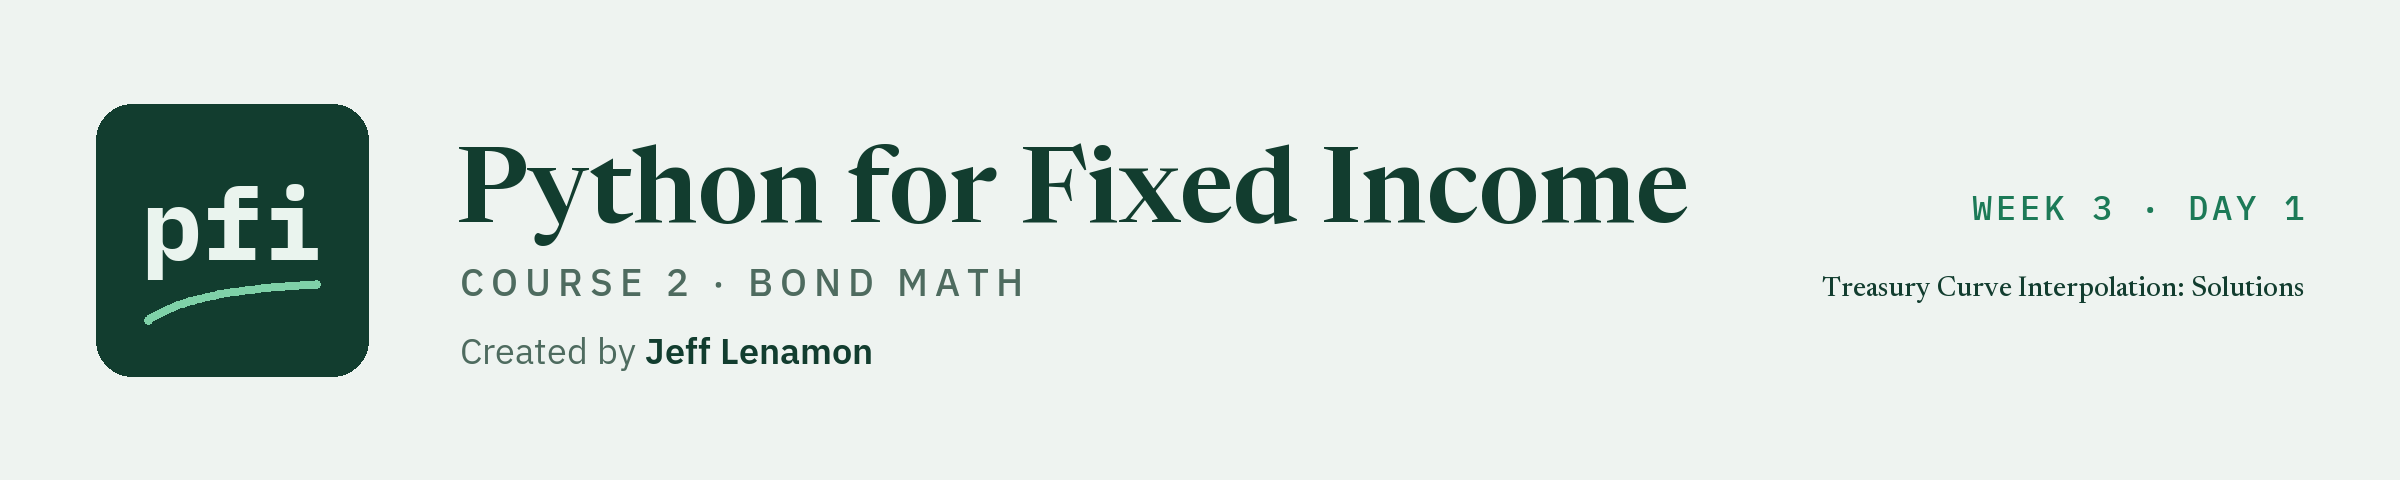

# Treasury Curve Interpolation: Solutions

Week 3, Day 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day1/11_treasury_curve_interpolation_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports and the curve of 30 September, `check`, and the curve of 2 October.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 11 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(11, after=11)

Work folder pfi_course2_11_k4w7q2xr: 4 data files, the module as notebook 11 left it, 11 commits, tagged week1 and week2


In [2]:
import importlib

import numpy as np
import pandas as pd

import bondmath
treasury = pd.read_csv('treasury_par_yields.csv', index_col='date')
curve_row = treasury.loc['2026-09-30']
tenor_years = {'1 Mo': 1 / 12, '1.5 Month': 1.5 / 12, '2 Mo': 2 / 12, '3 Mo': 3 / 12,
               '4 Mo': 4 / 12, '6 Mo': 0.5, '1 Yr': 1, '2 Yr': 2, '3 Yr': 3, '5 Yr': 5,
               '7 Yr': 7, '10 Yr': 10, '20 Yr': 20, '30 Yr': 30}
real_tenors = [tenor_years[label] for label in curve_row.index]
real_yields = curve_row.tolist()

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
second_row = treasury.loc['2026-10-02']
print(second_row.tolist())

[4.04, 4.09, 4.11, 4.19, 4.26, 4.27, 4.46, 4.83, 4.96, 5.06, 5.17, 5.28, 5.67, 5.63]


### Exercise 1

In [5]:
second_yields = second_row.tolist()
ex1_6_4 = bondmath.interpolate_yield(6.4, real_tenors, second_yields)
ex1_15 = bondmath.interpolate_yield(15, real_tenors, second_yields)
# the change since 30 September, in bp: 1 percent is 100 bp
ex1_change_bp = (ex1_6_4 - bondmath.interpolate_yield(6.4, real_tenors, real_yields)) * 100
print(f'6.4 years: {ex1_6_4:.3f}; 15 years: {ex1_15:.3f} percent; change {ex1_change_bp:.1f} bp')

6.4 years: 5.137; 15 years: 5.475 percent; change -2.3 bp


In [6]:
check('Exercise 1 yield at 6.4 years', ex1_6_4, 5.137)
check('Exercise 1 yield at 15 years', ex1_15, 5.475)
check('Exercise 1 change at 6.4 years in bp', ex1_change_bp, -2.3000000000000576)

Exercise 1 yield at 6.4 years: correct
Exercise 1 yield at 15 years: correct
Exercise 1 change at 6.4 years in bp: correct


The labels are the same on both dates, so the tenors in years are too.
In Excel, the 11.3 formula on the 2 October yields returns 5.1370000000000005 and 5.475.

### Exercise 2

In [7]:
invented = pd.read_csv('course2_treasury_curve.csv')
ex2_line = bondmath.interpolate_yield(0.92, invented['tenor_years'].tolist(),
                                      invented['yield_pct'].tolist())
ex2_formula = 3.55 + 1.05 * (1 - np.exp(-0.92 / 7))
ex2_gap_bp = (ex2_formula - ex2_line) * 100
print(f'line {ex2_line:.5f}, formula {ex2_formula:.5f} percent: {ex2_gap_bp:.4f} bp')

line 3.67912, formula 3.67932 percent: 0.0196 bp


In [8]:
check('Exercise 2 the straight line', ex2_line, 3.67912)
check('Exercise 2 the formula', ex2_formula, 3.679316000311106)
check('Exercise 2 gap in bp', ex2_gap_bp, 0.019600031110567073)

Exercise 2 the straight line: correct
Exercise 2 the formula: correct
Exercise 2 gap in bp: correct


0.92 years lies between the 0.5 and 1-year points, only half a year apart, so the line has little room to leave the curve: 0.02 bp, against 3.33 between 10 and 20 years.
In Excel, the formula on the invented curve returns 3.6791199999999993.

### Exercise 3

In [9]:
%%writefile -a bondmath.py


def tenor_label_to_years(label: str) -> float:
    """Years in one of Treasury's tenor labels, such as '3 Mo', '1.5 Month' or '10 Yr'.

    Units: the result is in years. Convention: Mo and Month are months, twelfths of a year;
    Yr is years. Raises ValueError for any other unit.
    """
    # the number, then the unit, split at the space
    number, unit = label.split()
    if unit in ('Mo', 'Month'):
        return float(number) / 12
    if unit == 'Yr':
        return float(number)
    raise ValueError(f'unknown tenor unit in {label!r}')

Appending to bondmath.py


In [10]:
%%writefile -a test_bondmath.py


def test_tenor_label_to_years_cases():
    assert bondmath.tenor_label_to_years("1 Mo") == pytest.approx(1 / 12, abs=1e-12)
    assert bondmath.tenor_label_to_years("1.5 Month") == 0.125
    assert bondmath.tenor_label_to_years("3 Mo") == 0.25
    assert bondmath.tenor_label_to_years("30 Yr") == 30
    with pytest.raises(ValueError):
        bondmath.tenor_label_to_years("3 Wk")

Appending to test_bondmath.py


In [11]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.................................                                        [100%]
33 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(bondmath)
ex3_three_months = bondmath.tenor_label_to_years('3 Mo')
years = [bondmath.tenor_label_to_years(label) for label in treasury.columns]
ex3_under_one_year = len([y for y in years if y < 1])
check('Exercise 3 3 Mo in years', ex3_three_months, 0.25)
check('Exercise 3 labels under one year', ex3_under_one_year, 6)

Exercise 3 3 Mo in years: correct
Exercise 3 labels under one year: correct


The function replaces 11.1's typed dictionary: it reads any label Treasury writes in `Mo`, `Month` or `Yr`.

### Exercise 4: AI check

The bug: only the `1.5 Month` label is divided by 12, so every `Mo` label is read in years: `3 Mo` as 3 years, `6 Mo` as 6.
Sorted, the misread tenors still make a curve `np.interp` reads without a word, so only a test against known values finds it: 4.674 at 6.4 years against 11.2's 5.16 by hand.
The fix divides both month spellings.

In [13]:
# written for this course in the style of an AI assistant's answer, now fixed
def assistant_treasury_yield_at(row, tenor_years):
    """Yield in percent at tenor_years on one row of treasury_par_yields.csv, straight between
    the published tenors and flat beyond the ends. Labels such as '3 Mo', '1.5 Month' and
    '10 Yr' become years first: months are twelfths of a year."""
    published = row.dropna()
    tenors, yields = [], []
    for label, yield_pct in zip(published.index, published.values):
        number = float(label.split()[0])
        # the fix: Treasury writes month tenors as Mo or as Month
        if label.endswith('Mo') or label.endswith('Month'):
            number = number / 12
        tenors.append(number)
        yields.append(yield_pct)
    # sort by tenor, so np.interp gets its points in order
    points = sorted(zip(tenors, yields))
    return float(np.interp(tenor_years, [t for t, _ in points], [y for _, y in points]))

In [14]:
# Excel's formula on the 30 September curve, as 11.3 recorded it
excel_real = {6.4: 5.160000000000001, 0.5: 4.330000000000001, 2.5: 4.9399999999999995,
              8.5: 5.24, 15: 5.484999999999999, 25: 5.66, 10: 5.29}
for tenor, excel_value in excel_real.items():
    result = assistant_treasury_yield_at(curve_row, tenor)
    assert abs(result - excel_value) < 1e-9, f'{tenor} years: {result}, Excel {excel_value}'
print("Every tenor matches Excel's formula")

Every tenor matches Excel's formula


In [15]:
ex4_6_4 = assistant_treasury_yield_at(curve_row, 6.4)
ex4_0_5 = assistant_treasury_yield_at(curve_row, 0.5)
check('Exercise 4 yield at 6.4 years', ex4_6_4, 5.16)
check('Exercise 4 yield at 0.5 years', ex4_0_5, 4.33)

Exercise 4 yield at 6.4 years: correct
Exercise 4 yield at 0.5 years: correct
